# Predicting halo station-keeping Δv with a polynomial NARX

**Question:** Given a burn time, can one sparse polynomial NARX predict the three Δv components calculated by the STM reference?

STM means **state transition matrix**: it estimates how a small change now affects the future orbit. The reference procedure checks departure eight times per orbit. At **at least 50 km** position departure or **at least 0.5 m/s** velocity departure, it tries burns now or 22.5°, 45°, or 67.5° later in the orbit cycle. It solves for Δv, verifies the candidate with nonlinear propagation, rejects burns above 10 m/s or without improvement, and selects the lowest departure cost with a small fuel penalty. It schedules no second burn while one is pending.

**This experiment supplies those burn times to NARX. It does not predict timing or burn/no-burn.** Waiting time is an input, because a correction depends on when it will be applied. Phase here means elapsed time through the halo period, not a geometric angle. Gateway tracking is outside this notebook's prediction objective.

## Model and data

The inputs are rotating-frame position departure [km], velocity departure [m/s], and sine/cosine of current orbital phase. The model uses four input samples (current plus three previous), four previous issued Δv commands [m/s], and the supplied wait as a fraction of an orbit. The outputs are rotating-frame Δv x/y/z [m/s]. Previous **issued** commands are distinct from burns executed later.

\[
z_k=[x_k,x_{k-1},x_{k-2},x_{k-3},u_{k-1},\ldots,u_{k-4},\tau_k/T],
\qquad \hat u_{j,k}=b_j+\sum_i a_{ji}\tilde z_{i,k}+\sum_{i\leq l}c_{jil}\tilde z_{i,k}\tilde z_{l,k}.
\]

There are 45 scalar regressors and 1,080 possible linear/quadratic terms before removing constant terms. Each component uses a sparse subset selected by orthogonal matching pursuit. Validation chooses among 1, 2, 4, 8, or 12 terms per component. All scaling is fitted on training burns only. The displayed coefficients refer to standardized regressors and standardized polynomial terms.

Training uses STM command history. Validation and test recursively feed back NARX commands after a common four-decision STM startup. No-burn decisions and rejected predictions insert zero issued commands; raw predictions are still scored without clipping. Metrics exclude startup, rejected reference targets, and histories containing unknown targets. Whole trajectories are split into training, validation, and test; test targets do not select coefficients or model size.

In [1]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT/'configs').exists(): ROOT = ROOT.parent
os.chdir(ROOT)
from halo_tracking.study import load_config
from halo_tracking.closed_loop_narx import generate_closed_loop_dataset
from halo_tracking.narx_audit import audit_dataset
from halo_tracking.polynomial_narx import fit_polynomial_narx
from halo_tracking.polynomial_experiment import run_polynomial_pair
cfg = load_config()
cfg['narx']['closed_loop_measurement_cadence_s'] = 21600.
OUT = ROOT/'artifacts'/'polynomial_narx'
OUT.mkdir(parents=True,exist_ok=True)
dataset = ROOT/'artifacts'/'neural_narx'/'teacher_training'  # Existing STM data, not neural predictions.
nb00 = ROOT/'notebooks'/'00_gateway_tracking_comparison.ipynb'
original_hash = hashlib.sha256(nb00.read_bytes()).hexdigest()
if not all((dataset/(s+'.npz')).exists() for s in ('training','validation','test')):
    generate_closed_loop_dataset(cfg,dataset)
audit = audit_dataset(dataset,cfg)
(OUT/'audit.json').write_text(json.dumps(audit,indent=2)+'\n')
model, stats = fit_polynomial_narx(dataset,cfg,OUT)
r = dict(np.load(OUT/'held_out_predictions.npz'))
print('Selected maximum terms per Δv component:',stats['selected_max_terms_per_component'])
print('Decision spacing [days]:',audit['training']['decision_spacing_days'])
print('Measurements every 6 hours, plus decision epochs; no cadence change at deployment.')
BLUE, ORANGE = 'tab:blue','tab:orange'
def table(headers,rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
        '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))
table(['Split','Trajectories','Scored burns','Recursive vector RMSE [m/s]'],[
    (s,q['arcs'],q['usable_burns'],f"{q['recursive']['vector_rmse_m_s']:.4f}") for s,q in stats['splits'].items()])

Selected maximum terms per Δv component: 4
Decision spacing [days]: 1.007259102764151
Measurements every 6 hours, plus decision epochs; no cadence change at deployment.


| Split | Trajectories | Scored burns | Recursive vector RMSE [m/s] |
| --- | --- | --- | --- |
| training | 20 | 41 | 0.2871 |
| validation | 5 | 8 | 0.2513 |
| test | 5 | 9 | 0.3170 |

## 1. Predicted Δv versus STM reference

Only held-out **burn decisions** are shown; thousands of easy no-burn zeros cannot hide the burn error. The burn times are supplied, not predicted. The points combine five separate test trajectories.

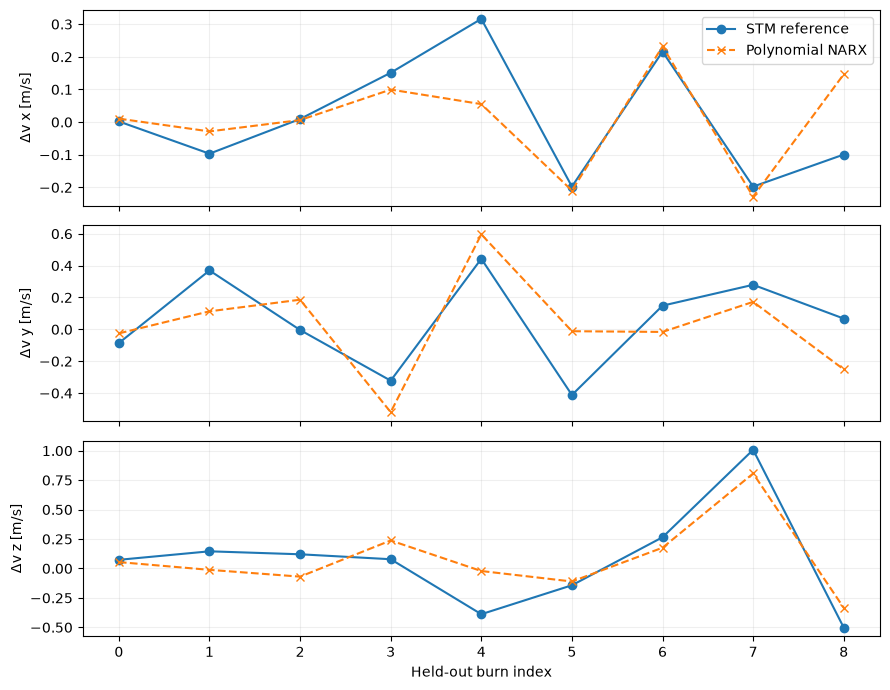

In [2]:
mask = r['mask']; truth = r['reference'][mask]; prediction = r['predicted'][mask]
ids = np.arange(len(truth))
fig,axes = plt.subplots(3,1,figsize=(9,7),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(ids,truth[:,j],'o-',color=BLUE,label='STM reference')
    ax.plot(ids,prediction[:,j],'x--',color=ORANGE,label='Polynomial NARX')
    ax.set_ylabel(f'Δv {"xyz"[j]} [m/s]'); ax.grid(alpha=.2)
axes[0].legend(); axes[-1].set_xlabel('Held-out burn index')
fig.tight_layout(); fig.savefig(OUT/'predicted_vs_stm.png',dpi=130); plt.show()

## 2. Prediction residuals

Residual means **NARX minus STM**. Zero is an exact match. The last panel shows the size of the three-component error. These are command errors, not spacecraft position errors.

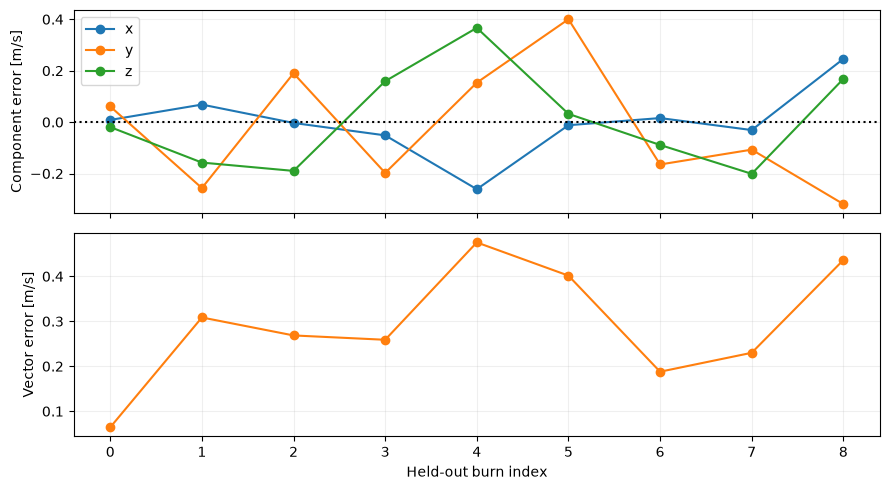

| Statistic | Held-out result |
| --- | --- |
| Vector RMSE [m/s] | 0.3170 |
| Component RMSE x/y/z [m/s] | [0.1235, 0.2281, 0.1821] |
| Component bias x/y/z [m/s] | [-0.0023, -0.0267, 0.0077] |
| Maximum vector error [m/s] | 0.4754 |
| Nonfinite burn predictions | 0 |

In [3]:
error = prediction-truth
fig,axes = plt.subplots(2,1,figsize=(9,5),sharex=True)
for j in range(3): axes[0].plot(ids,error[:,j],'o-',label='xyz'[j])
axes[0].axhline(0,color='black',ls=':'); axes[0].legend(); axes[0].set_ylabel('Component error [m/s]')
axes[1].plot(ids,np.linalg.norm(error,axis=1),'o-',color=ORANGE)
axes[1].set(ylabel='Vector error [m/s]',xlabel='Held-out burn index')
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'prediction_residuals.png',dpi=130); plt.show()
q = stats['splits']['test']['recursive']
table(['Statistic','Held-out result'],[
    ('Vector RMSE [m/s]',f"{q['vector_rmse_m_s']:.4f}"),
    ('Component RMSE x/y/z [m/s]',np.round(q['component_rmse_m_s'],4).tolist()),
    ('Component bias x/y/z [m/s]',np.round(q['component_bias_m_s'],4).tolist()),
    ('Maximum vector error [m/s]',f"{q['maximum_vector_error_m_s']:.4f}"),
    ('Nonfinite burn predictions',q['nonfinite_burns'])])

## 3. Apply the predicted Δv in the nonlinear orbit simulation

The planned span is **365 days**. First run STM and record its burn schedule. Then run polynomial NARX with that same schedule, initial conditions, and epoch-indexed measurement noise. NARX uses its own evolving estimated state and previous issued commands. The first four decisions share STM commands so both runs start with the same history.

**This is a conditional Δv experiment, not autonomous station keeping:** the reference run supplies future burn times. NARX neither replans timing as its orbit diverges nor receives replacement Δv after startup. Position/velocity departure measures error relative to the nominal halo orbit. Cumulative Δv sums the magnitudes of executed burns. A curve ends at the 20,000 km departure cutoff or a numerical failure, with no filled future values. One paired trial is not a Monte Carlo success-rate estimate.

STM: {"completed_requested_span": true, "last_simulated_day": 365.0, "stop_reason": "completed requested span", "maximum_position_departure_km": 148.91296563672816, "maximum_velocity_departure_m_s": 3.9217118154584036, "cumulative_delta_v_m_s": 39.80556080902093, "rejected_burns": 0, "executed_burns": 64}
Polynomial NARX: {"completed_requested_span": false, "last_simulated_day": 43.312141418858495, "stop_reason": "departure_cutoff", "maximum_position_departure_km": 33412.8959597768, "maximum_velocity_departure_m_s": 472.11843366049715, "cumulative_delta_v_m_s": 8.30275465259305, "rejected_burns": 2, "executed_burns": 5, "maximum_input_training_standard_deviations": 386.42133047873534, "first_day_above_10_training_standard_deviations": 20.14518205528302}


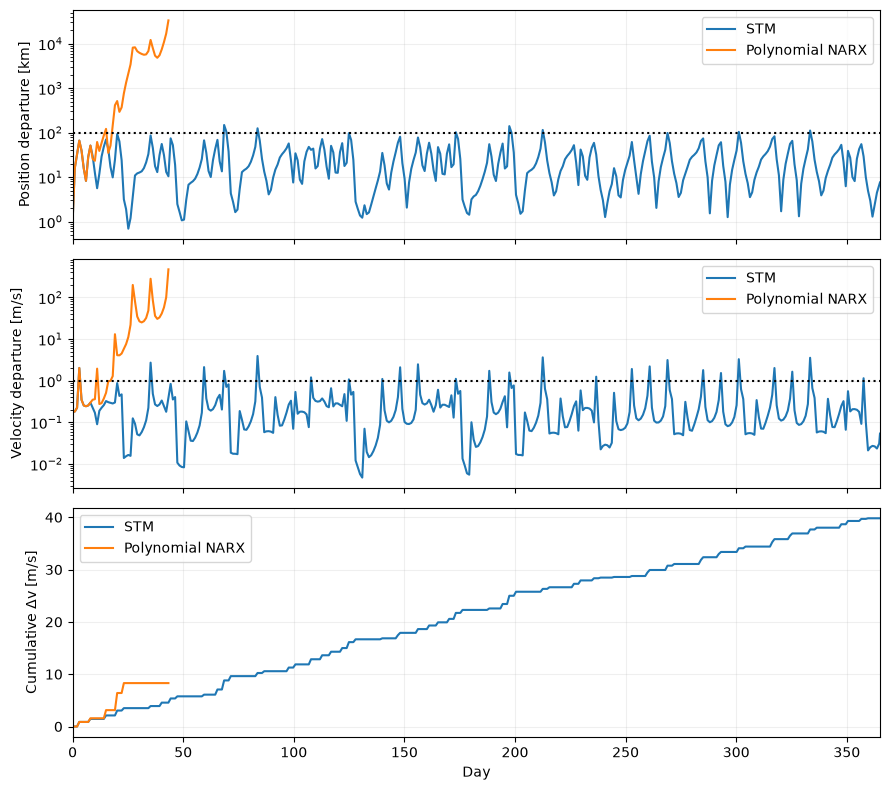

| Method | Last day | Executed burns | Δv [m/s] | Termination |
| --- | --- | --- | --- | --- |
| STM | 365.0 | 64 | 39.806 | completed requested span |
| Polynomial NARX | 43.3 | 5 | 8.303 | departure_cutoff |

In [4]:
episodes,orbit_stats = run_polynomial_pair(cfg,model,OUT/'orbit',days=365,seed=24017)
fig,axes = plt.subplots(3,1,figsize=(9,8),sharex=True)
for label,color in [('STM',BLUE),('Polynomial NARX',ORANGE)]:
    e = episodes[label]
    for ax,key in zip(axes[:2],('observer_truth_position_departure_km','observer_truth_velocity_departure_m_s')):
        ax.plot(e['day'],e[key],label=label,color=color)
    finite = np.isfinite(e['observer_truth_position_departure_km'])
    axes[2].plot(e['day'][finite],np.cumsum(e['delta_v_cost_m_s'])[finite],label=label,color=color)
axes[0].axhline(100,color='black',ls=':'); axes[1].axhline(1,color='black',ls=':')
axes[0].set(yscale='log',ylabel='Position departure [km]')
axes[1].set(yscale='log',ylabel='Velocity departure [m/s]')
axes[2].set(ylabel='Cumulative Δv [m/s]',xlabel='Day',xlim=(0,365))
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'orbit_departure_and_delta_v.png',dpi=130); plt.show()
table(['Method','Last day','Executed burns','Δv [m/s]','Termination'],[
    (label,f"{orbit_stats[label]['last_simulated_day']:.1f}",orbit_stats[label]['executed_burns'],
     f"{orbit_stats[label]['cumulative_delta_v_m_s']:.3f}",orbit_stats[label]['stop_reason']) for label in episodes])

## 4. What can explain the differences?

STM recalculates sensitivity from orbital dynamics and checks each proposed correction by nonlinear propagation. Polynomial NARX approximates its command mapping from a small set of examples. Quadratic terms are local approximations; outside the training range, they may grow rapidly. Recursively feeding back imperfect commands can introduce additional error. The fixed reference schedule may also become inappropriate once the NARX orbit diverges.

The following data checks show limited coverage and whether replacing past reference commands with predicted commands worsens held-out error. They help identify limitations, but do not prove a single cause or that all NARX models fail. A successful Δv comparison would still require separate evaluation of timing and Gateway tracking.

In [5]:
table(['Waiting phase [deg]','Training burns','Test burns'],[
    (phase,stats['splits']['training']['wait_phase_counts'][phase],stats['splits']['test']['wait_phase_counts'][phase])
    for phase in stats['splits']['training']['wait_phase_counts']])
table(['Feedback used in held-out test','Vector RMSE [m/s]'],[
    ('Previous STM commands (diagnostic)',stats['splits']['test']['reference_history']['vector_rmse_m_s']),
    ('Previous NARX commands (main result)',stats['splits']['test']['recursive']['vector_rmse_m_s'])])
print('Sparse equations, in standardized coordinates:')
for axis,equation in zip('xyz',stats['coefficients_in_standardized_coordinates']):
    print(axis,json.dumps(equation))
trial = orbit_stats['Polynomial NARX']
print('Rejected polynomial burns:',trial['rejected_burns'])
print('Maximum input distance in training standard deviations:',trial['maximum_input_training_standard_deviations'])
print('First burn decision above ten training standard deviations [day]:',trial['first_day_above_10_training_standard_deviations'])
print('Large standardized inputs show extrapolation, not calibrated uncertainty or proof of the first failure cause.')
print(f"Observed result: held-out burn-vector RMSE = {q['vector_rmse_m_s']:.3f} m/s; "
      f"polynomial orbit ends on day {trial['last_simulated_day']:.1f}: {trial['stop_reason']}.")
assert hashlib.sha256(nb00.read_bytes()).hexdigest()==original_hash
print('Notebook 00 unchanged. Three plots, fitted model, coefficients, audit and numerical histories saved.')

Sparse equations, in standardized coordinates:
x {"intercept_m_s": 0.044015510423842615, "terms": [{"term": "rx[k-0]", "coefficient_m_s": -0.11213584587708535}, {"term": "sin_phase[k-3] vz[k-0]", "coefficient_m_s": -0.07261560243644584}, {"term": "sin_phase[k-1] rz[k-0]", "coefficient_m_s": -0.058034121719627046}, {"term": "rx[k-0] wait_fraction", "coefficient_m_s": 0.1362434259893148}]}
y {"intercept_m_s": -0.009760127024016055, "terms": [{"term": "vz[k-0]", "coefficient_m_s": -0.27035971200032005}, {"term": "vz[k-2] sin_phase[k-1]", "coefficient_m_s": -0.14768467598480325}, {"term": "sin_phase[k-2] ry[k-1]", "coefficient_m_s": 0.1978350974224004}, {"term": "sin_phase[k-0] dvz[k-3]", "coefficient_m_s": 0.3848424056885903}]}
z {"intercept_m_s": -0.03589611360354769, "terms": [{"term": "cos_phase[k-3] rz[k-0]", "coefficient_m_s": 0.13976736938112053}, {"term": "sin_phase[k-2] vz[k-0]", "coefficient_m_s": 0.18750332937658679}, {"term": "rz[k-0] wait_fraction", "coefficient_m_s": 0.321376

| Waiting phase [deg] | Training burns | Test burns |
| --- | --- | --- |
| 0 | 31 | 6 |
| 22.5 | 0 | 2 |
| 45.0 | 0 | 0 |
| 67.5 | 10 | 1 |

| Feedback used in held-out test | Vector RMSE [m/s] |
| --- | --- |
| Previous STM commands (diagnostic) | 0.3182746464360336 |
| Previous NARX commands (main result) | 0.3169557221219605 |